# 🎯 Task-Specific EDA: Machine Translation & Text Rewriting
## Bilingual Length Ratio, Word Fertility, Cross-Lingual Overlap & Metric Bounds
**Kit:** `02_NLG/02_machine_translation_and_rewriting` | **Standard:** GEMASTIK XIX 2026 & Kaggle NLP  
**Focus:** Sequence-to-Sequence Translation, Low-Resource Alignment, BLEU, chrF, and ROUGE evaluation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv('../demo_data/train.csv')
test_df  = pd.read_csv('../demo_data/test.csv')

SOURCE_COL = 'source_text'
TARGET_COL = 'target_text'

print(f"Train Parallel Pairs: {len(train_df)} | Test Pairs: {len(test_df)}")
train_df.head()


Train Parallel Pairs: 40 | Test Pairs: 10


,id,source_text,target_text
0,TRN_000,Kecerdasan buatan berkembang sangat pesat di e...,Artificial intelligence is developing very rap...
1,TRN_001,Pemerintah mendorong transformasi digital di s...,The government encourages digital transformati...
2,TRN_002,Mahasiswa Indonesia berhasil meraih medali ema...,Indonesian students succeeded in winning gold ...
3,TRN_003,Pariwisata berkelanjutan menjadi fokus utama p...,Sustainable tourism has become the main focus ...
4,TRN_004,Inovasi teknologi finansial mempermudah akses ...,Financial technology innovation facilitates ba...


In [2]:
# Length and Word Fertility Ratio
train_df['src_len'] = train_df[SOURCE_COL].astype(str).apply(lambda x: len(x.split()))
train_df['tgt_len'] = train_df[TARGET_COL].astype(str).apply(lambda x: len(x.split()))
train_df['fertility_ratio'] = train_df['tgt_len'] / (train_df['src_len'] + 1e-5)

mean_ratio = train_df['fertility_ratio'].mean()
print("--- BILINGUAL LENGTH STATISTICS ---")
print(f"Source Mean Words : {train_df['src_len'].mean():.1f} (Max: {train_df['src_len'].max()})")
print(f"Target Mean Words : {train_df['tgt_len'].mean():.1f} (Max: {train_df['tgt_len'].max()})")
print(f"Mean Word Fertility: {mean_ratio:.2f} (Target length relative to source)")


--- BILINGUAL LENGTH STATISTICS ---
Source Mean Words : 8.6 (Max: 11)
Target Mean Words : 10.0 (Max: 11)
Mean Word Fertility: 1.18 (Target length relative to source)


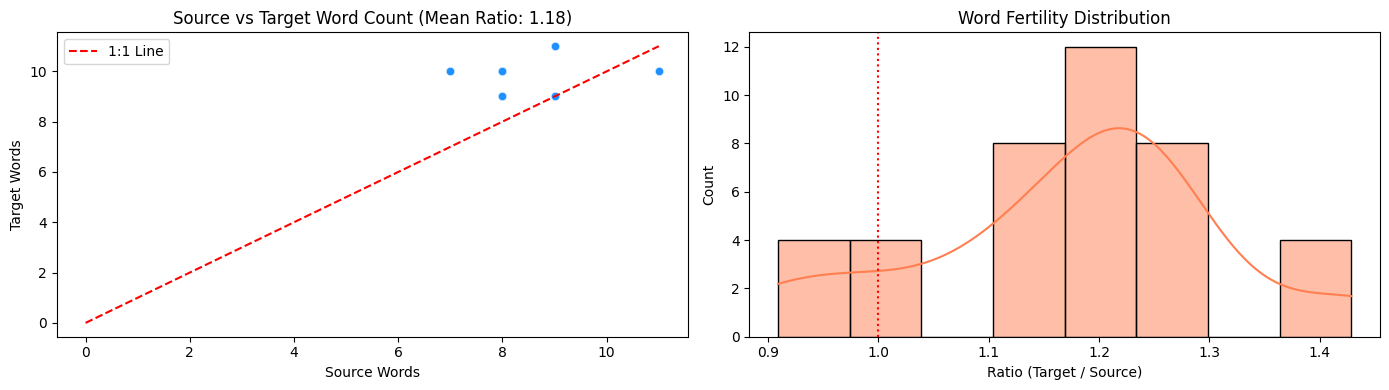

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.scatterplot(data=train_df, x='src_len', y='tgt_len', ax=axes[0], color='dodgerblue', alpha=0.7)
axes[0].plot([0, train_df['src_len'].max()], [0, train_df['src_len'].max()], 'r--', label='1:1 Line')
axes[0].set_title(f"Source vs Target Word Count (Mean Ratio: {mean_ratio:.2f})")
axes[0].set_xlabel("Source Words")
axes[0].set_ylabel("Target Words")
axes[0].legend()

sns.histplot(train_df['fertility_ratio'], ax=axes[1], color='coral', kde=True)
axes[1].axvline(1.0, color='red', linestyle=':')
axes[1].set_title("Word Fertility Distribution")
axes[1].set_xlabel("Ratio (Target / Source)")

plt.tight_layout()
plt.show()


In [4]:
# Vocabulary Overlap (Detect named entities & untranslated borrowings)
src_vocab = set(" ".join(train_df[SOURCE_COL].astype(str)).lower().split())
tgt_vocab = set(" ".join(train_df[TARGET_COL].astype(str)).lower().split())
shared_vocab = src_vocab.intersection(tgt_vocab)

print(f"Source Vocabulary Size : {len(src_vocab)}")
print(f"Target Vocabulary Size : {len(tgt_vocab)}")
print(f"Shared Borrowings/Tokens: {len(shared_vocab)} ({len(shared_vocab)/len(src_vocab)*100:.1f}% of source)")
print("Shared Sample:", list(shared_vocab)[:10])


Source Vocabulary Size : 79
Target Vocabulary Size : 82
Shared Borrowings/Tokens: 4 (5.1% of source)
Shared Sample: ['asia', 'science', 'digital', 'data']


### 📋 Master Decision Matrix (Machine Translation & Text Rewriting):
| Diagnostic Signal | Finding | Recommended Strategy |
| :--- | :--- | :--- |
| **Fertility Ratio** | Ratio $\approx 1.0 - 1.2$ | Standard sequence length mapping; set `max_target_length = max_source_length * 1.3`. |
| **Fertility Ratio Outliers** | Ratio $< 0.3$ or $> 3.0$ | Filter out corrupted training pairs with bilingual length filtering. |
| **Metric Target** | BLEU / chrF | Apply beam search (`num_beams=4`) with length penalty and post-processing detokenization. |
| **Borrowing Overlap** | High named entity sharing | Retain untranslated capitalized entities (people, org names) using copy-attention mechanism. |
